# Klasifikacija toksičnih tvitova

In [261]:
import re
import unicodedata
import string

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from wordcloud import WordCloud

import nltk
from nltk.tokenize import word_tokenize, TweetTokenizer
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer
from nltk import pos_tag

import emoji
from spellchecker import SpellChecker

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from sklearn.preprocessing import MaxAbsScaler

import torch
from transformers import AutoTokenizer, AutoModel

import gensim
from gensim.models import Word2Vec

from sklearn.model_selection import train_test_split
import nlpaug.augmenter.word as naw
from transformers import pipeline

from transformers import MarianTokenizer, MarianMTModel
from transformers import T5ForConditionalGeneration, T5Tokenizer
import html as html_module

from gensim.models import FastText

import contractions

import warnings
warnings.filterwarnings('ignore')

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_colwidth', 120)

In [262]:
sns.set_theme(palette="pastel")

## Učitavanje dataseta

In [263]:
df = pd.read_csv('twitter_toxic_tweets.csv')
print(df.shape)
df[5:10]

(31962, 3)


,id,label,tweet
5,6,0,[2/2] huge fan fare and big talking before they leave. chaos and pay disputes when they get there. #allshowandnogo
6,7,0,@user camping tomorrow @user @user @user @user @user @user @user dannyâ¦
7,8,0,the next school year is the year for exams.ð¯ can't think about that ð­ #school #exams #hate #imagine #actorsl...
8,9,0,we won!!! love the land!!! #allin #cavs #champions #cleveland #clevelandcavaliers â¦
9,10,0,@user @user welcome here ! i'm it's so #gr8 !


In [264]:
def fix_text_for_emoji(text):
    try:
        return text.encode('latin1').decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        return text

df['tweet'] = df['tweet'].apply(fix_text_for_emoji)
df[5:10]

,id,label,tweet
5,6,0,[2/2] huge fan fare and big talking before they leave. chaos and pay disputes when they get there. #allshowandnogo
6,7,0,@user camping tomorrow @user @user @user @user @user @user @user danny…
7,8,0,the next school year is the year for exams.😯 can't think about that 😭 #school #exams #hate #imagine #actorslife #r...
8,9,0,we won!!! love the land!!! #allin #cavs #champions #cleveland #clevelandcavaliers …
9,10,0,@user @user welcome here ! i'm it's so #gr8 !


In [265]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31962 entries, 0 to 31961
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      31962 non-null  int64 
 1   label   31962 non-null  int64 
 2   tweet   31962 non-null  object
dtypes: int64(2), object(1)
memory usage: 749.2+ KB


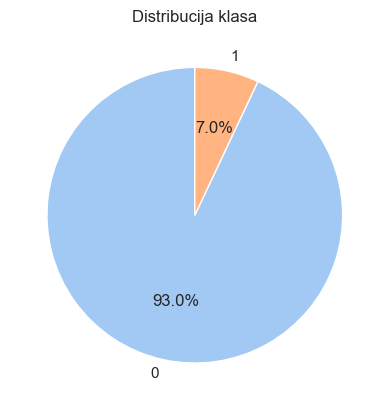

In [266]:
sentiment_counts = df['label'].value_counts()
labels = sentiment_counts.index
sizes = sentiment_counts.values

plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Distribucija klasa")
plt.show()

## Kvalitet tekstualnih podataka

### Dužina dokumenata

Dužina tvita meri se na dva načina: brojem karaktera i brojem tokena (reči). Za potrebe tokenizacije koristi se `TweetTokenizer` - specijalizovani tokenizator za tvitove. Distribucija dužine može se razlikovati između klasa - toksični tvitovi mogu biti kraći i direktniji, ili duži zbog upotrebe više uvreda.

In [267]:
tknzr = TweetTokenizer()
df['char_count'] = df['tweet'].str.len()
df['token_count'] = df['tweet'].apply(lambda x: len(tknzr.tokenize(str(x))))

stats = df.groupby('label')[['char_count', 'token_count']].agg(['min', 'max', 'mean', 'median'])
stats.columns = ['_'.join(c) for c in stats.columns]
stats.index = stats.index.map({0: 'Non-toxic', 1: 'Toxic'})
stats.round(1).T

label,Non-toxic,Toxic
char_count_min,10.0,12.0
char_count_max,181.0,143.0
char_count_mean,81.9,89.1
char_count_median,85.0,95.0
token_count_min,3.0,3.0
token_count_max,50.0,33.0
token_count_mean,15.2,16.1
token_count_median,15.0,16.0


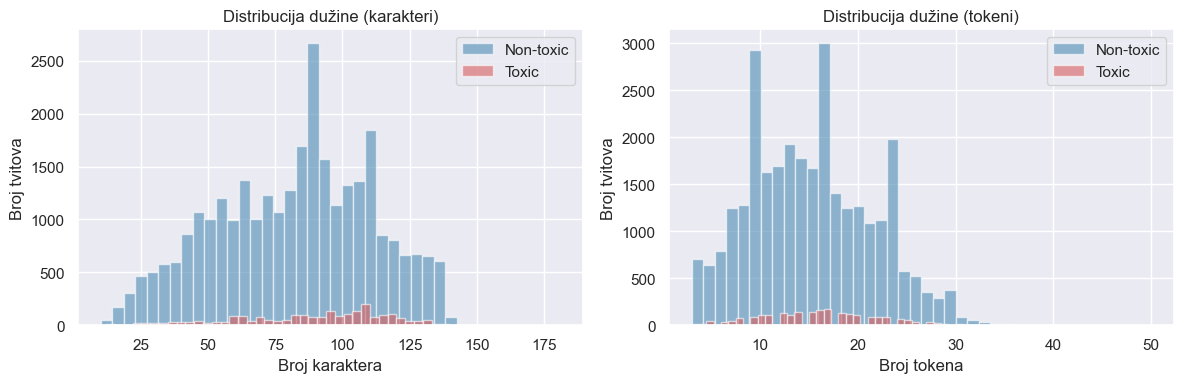

In [268]:
label_map = {0: 'Non-toxic', 1: 'Toxic'}
colors = {'Non-toxic': '#4C8BB5', 'Toxic': '#D95F5F'}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label_val, label_name in label_map.items():
    subset = df[df['label'] == label_val]
    axes[0].hist(subset['char_count'], bins=40, alpha=0.6, label=label_name, color=colors[label_name])
    axes[1].hist(subset['token_count'], bins=40, alpha=0.6, label=label_name, color=colors[label_name])

axes[0].set_title('Distribucija dužine (karakteri)')
axes[0].set_xlabel('Broj karaktera')
axes[0].set_ylabel('Broj tvitova')
axes[0].legend()

axes[1].set_title('Distribucija dužine (tokeni)')
axes[1].set_xlabel('Broj tokena')
axes[1].set_ylabel('Broj tvitova')
axes[1].legend()

plt.tight_layout()
plt.show()

### Veličina vokabulara

Veličina vokabulara označava broj jedinstvenih tokena u korpusu. Poređenje vokabulara između klasa može otkriti da li toksični tvitovi koriste specifičan skup reči.

In [269]:
def get_vocab(texts):
    tokens = [t for text in texts for t in tknzr.tokenize(str(text).lower())]
    return set(tokens), tokens

toxic_texts    = df[df['label'] == 1]['tweet']
nontoxic_texts = df[df['label'] == 0]['tweet']

vocab_all, tokens_all = get_vocab(df['tweet'])
vocab_toxic, tokens_toxic = get_vocab(toxic_texts)
vocab_nontox, tokens_nontox = get_vocab(nontoxic_texts)

vocab_stats = pd.DataFrame({
    'Korpus':             ['Ceo dataset', 'Toxic',          'Non-toxic'],
    'Ukupno tokena':      [len(tokens_all), len(tokens_toxic), len(tokens_nontox)],
    'Jedinstvenih tokena':[len(vocab_all),  len(vocab_toxic),  len(vocab_nontox)],
})
vocab_stats['Ekskluzivni tokeni'] = [
    '-',
    len(vocab_toxic - vocab_nontox),
    len(vocab_nontox - vocab_toxic)
]
vocab_stats

,Korpus,Ukupno tokena,Jedinstvenih tokena,Ekskluzivni tokeni
0,Ceo dataset,487335,48018,-
1,Toxic,36002,6666,2594
2,Non-toxic,451333,45424,41352


### Leksička raznovrsnost

Pošto postoji veliki broj instanci u datasetu, prirodno je da posle nekog vremena dosta reči počne da se ponavlja, što znači da će TTR biti nizak. Zbog toga se koristi **STTR (Standardized TTR)** koji računa prosečni TTR na prozorima fiksne veličine (u ovom slučaju 1000).

In [270]:
def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0

def sttr(tokens, window=200):
    chunks = [tokens[i:i+window] for i in range(0, len(tokens) - window + 1, window)]
    return np.mean([ttr(c) for c in chunks]) if chunks else 0

results = []
for label_val, label_name in [(None, 'Ceo dataset'), (1, 'Toxic'), (0, 'Non-toxic')]:
    texts = df['tweet'] if label_val is None else df[df['label'] == label_val]['tweet']
    tokens = [t for text in texts for t in tknzr.tokenize(str(text).lower())]
    results.append({
        'Korpus': label_name,
        'TTR':  round(ttr(tokens), 4),
        'STTR (w=200)': round(sttr(tokens), 4)
    })

pd.DataFrame(results)

,Korpus,TTR,STTR (w=200)
0,Ceo dataset,0.0985,0.7423
1,Toxic,0.1852,0.7134
2,Non-toxic,0.1006,0.7423


TTR vrednosti su veoma niske (0.08–0.17), što je očekivano za veliki korpus - što je korpus veći, reči se više ponavljaju i TTR pada. Toksični tvitovi imaju duplo veći TTR (0.1794) jer ih ima manje u datasetu, što potvrđuje da je dataset neuravnotežen.

STTR daje pouzdaniju sliku jer eliminiše uticaj veličine korpusa. Vrednosti su ujednačene između klasa (~0.7), što znači da su toksični i netoksični tvitovi podjednako leksički raznovrsni - ni jedna klasa ne koristi monotoniji ili repetitivniji rečnik od druge.

Generalno, STTR oko 0.7 je relativno visok, što je karakteristično za tvitove - kratki dokumenti prirodno imaju manje ponavljanja unutar prozora od 200 tokena nego npr. novinski članci ili knjige.

### Šum u tekstu

Tvitovi sadrže karakteristične vrste šuma koje nisu prisutne u standardnim tekstualnim korpusima: URL-ovi, `@mentions`, `#hashtags`, HTML entiteti, specijalni karakteri i emoji simboli. Ovde ih identifikujemo i vizualizujemo pre bilo kakve predobrade.

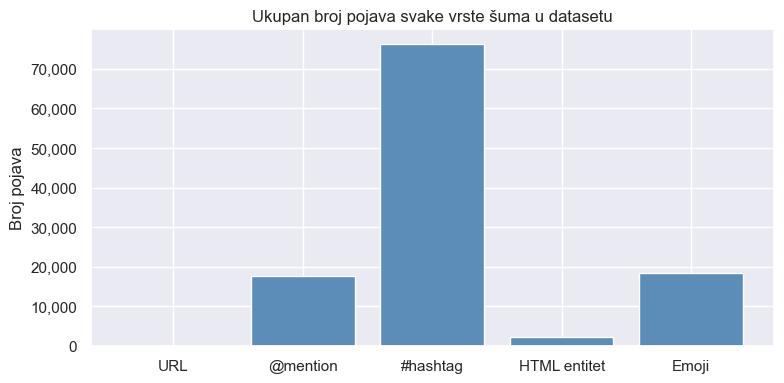


Brojevi pojava:
  URL                 : 6
  @mention            : 17,571
  #hashtag            : 76,155
  HTML entitet        : 2,256
  Emoji               : 18,364


In [271]:
noise_patterns = {
    'URL':            r'https?://\S+|www\.\S+',
    '@mention':       r'@\w+',
    '#hashtag':       r'#\w+',
    'HTML entitet':   r'&[a-z]+;|&#\d+;'
}

noise_counts = {name: df['tweet'].str.count(pat).sum() for name, pat in noise_patterns.items()}
noise_counts['Emoji'] = df['tweet'].apply(lambda x: emoji.emoji_count(str(x))).sum()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(noise_counts.keys(), noise_counts.values(), color='#5B8DB8')
ax.set_title('Ukupan broj pojava svake vrste šuma u datasetu')
ax.set_ylabel('Broj pojava')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()

print('\nBrojevi pojava:')
for k, v in noise_counts.items():
    print(f'  {k:20s}: {v:,}')

In [272]:
# Konkretni primeri svake vrste šuma iz dataseta
examples = {}
for name, pat in noise_patterns.items():
    mask = df['tweet'].str.contains(pat, regex=True, na=False)
    examples[name] = df[mask]['tweet'].iloc[0] if mask.any() else 'N/A'

emoji_mask = df['tweet'].apply(lambda x: emoji.emoji_count(str(x)) > 0)
examples['Emoji'] = df[emoji_mask]['tweet'].iloc[0] if emoji_mask.any() else 'N/A'

ex_df = pd.DataFrame({'Vrsta šuma': examples.keys(), 'Primer tvita': examples.values()})
ex_df

,Vrsta šuma,Primer tvita
0,URL,#fly #and #better #with #us #buranus #www.flybcc.com #call #7/24 #airbroker #flight…
1,@mention,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run
2,#hashtag,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run
3,HTML entitet,product of the day: happy man #wine tool who's it's the #weekend? time to open up &amp; drink up!
4,Emoji,#model i love u take with u all the time in ur📱!!! 😙😎👄👅💦💦💦


### Word cloud

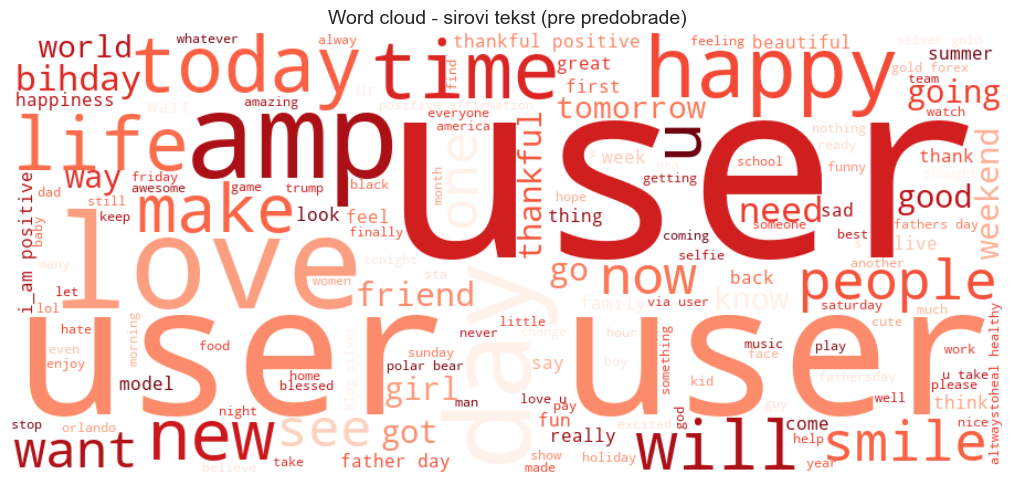

In [273]:
raw_text = ' '.join(df['tweet'].dropna().astype(str).tolist())

wc = WordCloud(width=900, height=400, background_color='white',
               max_words=150, colormap='Reds').generate(raw_text)

plt.figure(figsize=(12, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word cloud - sirovi tekst (pre predobrade)', fontsize=14)
plt.tight_layout()
plt.show()

## Predobrada podataka

Pipeline predobrade implementiran je korak po korak. Nakon svakog koraka prikazuje se tabela **pre $\rightarrow$ posle** na reprezentativnim primerima.

### Uklanjanje duplikata

In [274]:
print(f'Broj duplikata: {df.duplicated(subset="tweet").sum()}')
df[df.duplicated(subset='tweet', keep=False)].sort_values('tweet').head(5)

Broj duplikata: 2432


,id,label,tweet,char_count,token_count
22292,22293,0,#fathersday ! looking for something to do? see what's trending in your community at,87,15
27400,27401,0,#fathersday ! looking for something to do? see what's trending in your community at,87,15
12549,12550,0,#fathersday ! looking for something to do? see what's trending in your community at,87,15
31764,31765,0,#fathersday ! looking for something to do? see what's trending in your community at,87,15
9696,9697,0,#fathersday ! looking for something to do? see what's trending in your community at,87,15


In [275]:
df = df.drop_duplicates(subset='tweet').reset_index(drop=True)
print(f'Veličina dataseta nakon uklanjanja duplikata: {df.shape}')

Veličina dataseta nakon uklanjanja duplikata: (29530, 5)


### Train / test split

Podela se vrši **pre augmentacije** kako bi se sprečilo curenje podataka (data leakage) - augmentovani primeri iz trening skupa ne smeju dospeti u test skup.

In [276]:
X_train, X_test, y_train, y_test = train_test_split(
    df['tweet'], df['label'], test_size=0.2, random_state=42, stratify=df['label']
)

train_df = pd.DataFrame({'tweet': X_train, 'label': y_train}).reset_index(drop=True)
test_df  = pd.DataFrame({'tweet': X_test,  'label': y_test}).reset_index(drop=True)

print(f'Trening skup: {train_df.shape}')
print(f'Test skup:    {test_df.shape}')
print(f'\nDistribucija klasa - trening:')
print(train_df['label'].value_counts())

Trening skup: (23624, 2)
Test skup:    (5906, 2)

Distribucija klasa - trening:
label
0    22014
1     1610
Name: count, dtype: int64


### Augmentacija podataka

Dataset je neuravnotežen - manjinska klasa su toksični tvitovi. Augmentacija se primenjuje **isključivo na trening skupu** kako bi se izbalansirala distribucija klasa.

Koriste se tri pristupa opisana u teorijskom delu rada.

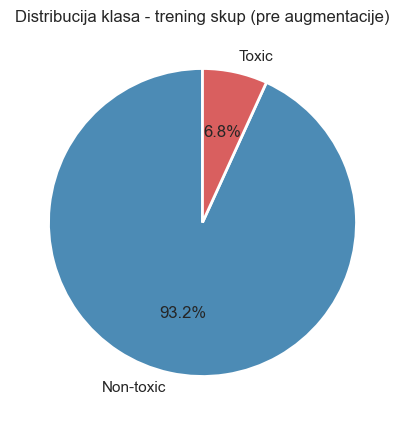

In [277]:
counts = train_df['label'].value_counts()
labels = counts.index.map({0: 'Non-toxic', 1: 'Toxic'})

plt.figure(figsize=(5, 5))
plt.pie(counts.values, labels=labels, autopct='%1.1f%%',
        startangle=90, colors=['#4C8BB5', '#D95F5F'],
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})
plt.title('Distribucija klasa - trening skup (pre augmentacije)')
plt.show()

#### Jednostavne tehnike augmentacije

In [278]:
aug_sr = naw.SynonymAug(aug_src='wordnet')   # Synonym Replacement
aug_rs = naw.RandomWordAug(action='swap')    # Random Swap
aug_rd = naw.RandomWordAug(action='delete')  # Random Deletion

toxic_tweets = train_df[train_df['label'] == 1]['tweet'].tolist()
sample = toxic_tweets[:3]

demo = pd.DataFrame({
    'Original':             sample,
    'Synonym Replacement':  aug_sr.augment(sample),
    'Random Swap':          aug_rs.augment(sample),
    'Random Deletion':      aug_rd.augment(sample),
})
demo

,Original,Synonym Replacement,Random Swap,Random Deletion
0,good afternoon sweety! 😃 send me letter ♋️,good good afternoon sweety! 😃 send me letter ♋ ️,good sweety afternoon! 😃 send me letter ♋ ️,good sweety! 😃 send letter ️
1,"well,these sewer rats don't take a cent from me,....i don't use to watch ""football"",......but now,i hate it!","well, these sewer betrayer assume ' t take a penny from me, .. .. ane don river ' thyroxin use to see "" football gam...",", well these sewer don rats t ' take a cent me from, .. .. i ' don use t to "" watch football "", .. .. . but. now i h...",", these rats ' t a from, .. .. i don ' t use to "" "", .. .. .. , i hate it!"
2,"@user #trump used #hate, and #putin to win the white house #trump presses attack on khan family and g.o.p. leaders","@ user # cornet used # hate, and # putin to win the bloodless mansion # trump presses attack on caravansary family l...","@ # user trump used # hate, and # to putin the white win house # trump presses khan on attack family g and. . o. p l...","@ user # # hate, and # putin win the white # presses khan and g. . p."


#### Backtranslation

In [279]:
def load_translator(model_name):
    tok = MarianTokenizer.from_pretrained(model_name)
    model = MarianMTModel.from_pretrained(model_name)
    def translate(texts):
        inputs = tok(texts, return_tensors='pt', padding=True, truncation=True, max_length=512)
        outputs = model.generate(**inputs)
        return [tok.decode(o, skip_special_tokens=True) for o in outputs]
    return translate

en_de = load_translator('Helsinki-NLP/opus-mt-en-de')
de_en = load_translator('Helsinki-NLP/opus-mt-de-en')

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


In [280]:
def backtranslate(texts):
    return de_en(en_de(texts))

sample_bt = toxic_tweets[:3]
bt_results = backtranslate(sample_bt)
pd.DataFrame({'Original': sample_bt, 'Backtranslation (EN -> DE -> EN)': bt_results})

,Original,Backtranslation (EN -> DE -> EN)
0,good afternoon sweety! 😃 send me letter ♋️,"Good afternoon, sweet!"
1,"well,these sewer rats don't take a cent from me,....i don't use to watch ""football"",......but now,i hate it!","Well, these canal rats don't take a cent of me,....I don't use it to see ""football,""...but now, I hate it!"
2,"@user #trump used #hate, and #putin to win the white house #trump presses attack on khan family and g.o.p. leaders",@user #trump used #hate and #putin to win the white house #trump presses attack on khan family and g.o.p. leader


#### Generativni modeli

In [281]:
tok_t5 = T5Tokenizer.from_pretrained('Vamsi/T5_Paraphrase_Paws')
model_t5 = T5ForConditionalGeneration.from_pretrained('Vamsi/T5_Paraphrase_Paws')

def paraphrase(texts):
    inputs = tok_t5(
        [f'paraphrase: {t} </s>' for t in texts],
        return_tensors='pt', padding=True, truncation=True, max_length=128
    )
    outputs = model_t5.generate(**inputs, max_length=128)
    return [tok_t5.decode(o, skip_special_tokens=True) for o in outputs]

sample_t5 = toxic_tweets[:3]
t5_results = paraphrase(sample_t5)
pd.DataFrame({'Original': sample_t5, 'T5 parafraziranje': t5_results})

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

,Original,T5 parafraziranje
0,good afternoon sweety! 😃 send me letter ♋️,Good afternoon sweety Send me a letter
1,"well,these sewer rats don't take a cent from me,....i don't use to watch ""football"",......but now,i hate it!","These sewer rats don't take a cent from me , i don't use to watch ""football"" , but now i hate it!"
2,"@user #trump used #hate, and #putin to win the white house #trump presses attack on khan family and g.o.p. leaders",@user #trump used #hate and #putin to win the White House #trump presses attack on Khan family and G.O.P. leaders


#### Augmentacija jednostavnim tehnikama

Koriste se jednostavne tehnike augmentacije jer je za backtranslation i parafraziranje potrebno dosta računarskih resursa i za veliki broj podataka to traje dugo.

In [282]:
n_majority = train_df['label'].value_counts()[0]
n_minority = train_df['label'].value_counts()[1]
n_needed   = int((n_majority - n_minority) * 0.5)

augmented_texts  = aug_sr.augment(toxic_tweets * ((n_needed // n_minority) + 1))
augmented_texts  = augmented_texts[:n_needed]

aug_df = pd.DataFrame({'tweet': augmented_texts, 'label': 1})
train_df = pd.concat([train_df, aug_df], ignore_index=True)
print(f'Trening skup nakon EDA augmentacije:')
print(train_df['label'].value_counts())

Trening skup nakon EDA augmentacije:
label
0    22014
1    11812
Name: count, dtype: int64


#### Distribucija klasa nakon augmentacije

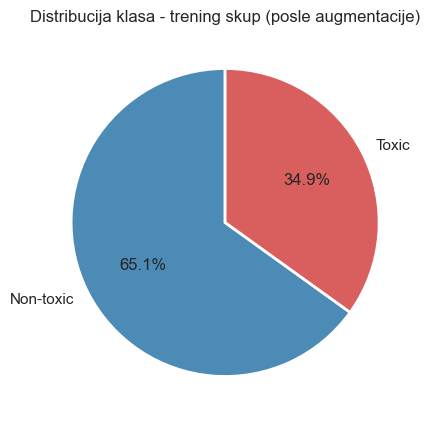

In [283]:
counts_aug = train_df['label'].value_counts()
labels_aug = counts_aug.index.map({0: 'Non-toxic', 1: 'Toxic'})

plt.figure(figsize=(5, 5))
plt.pie(counts_aug.values, labels=labels_aug, autopct='%1.1f%%',
        startangle=90, colors=['#4C8BB5', '#D95F5F'],
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})
plt.title('Distribucija klasa - trening skup (posle augmentacije)')
plt.show()

### Uklanjanje šuma

In [284]:
def remove_noise(text):
    text = re.sub(r'https?://\S+|www\.\S+', '', text)   # URL
    text = re.sub(r'@\w+', '', text)                      # @mention
    text = re.sub(r'#(\w+)', r'\1', text)                 # #hashtag → tekst
    text = html_module.unescape(text)                     # HTML entiteti
    text = text.translate(str.maketrans('', '', string.punctuation))  # interpunkcija
    text = re.sub(r'\s+', ' ', text).strip()              # višak whitespace
    return text

# Pre/posle prikaz
sample_idx = train_df[train_df['tweet'].str.contains('http|@|#', na=False)].index[:5]
pd.DataFrame({
    'Pre':  train_df.loc[sample_idx, 'tweet'].values,
    'Posle': train_df.loc[sample_idx, 'tweet'].apply(remove_noise).values
})

,Pre,Posle
0,it's actually stopped raining......for now.....so bike ride it is then!😊🚴🏻 #cycling #mtb …,its actually stopped rainingfor nowso bike ride it is then😊🚴🏻 cycling mtb …
1,@user to see you,to see you
2,@user stop...can't handle their drink or the heat along with bad manners and racism in a volatile city...,stopcant handle their drink or the heat along with bad manners and racism in a volatile city
3,everybody has somebody and i have nobody #single #depression #singlelife,everybody has somebody and i have nobody single depression singlelife
4,#iftar 🎂 or 🍥 #charming it is 😋 #cake #pie #foodporn #nomnom #foodie #love #food,iftar 🎂 or 🍥 charming it is 😋 cake pie foodporn nomnom foodie love food


In [285]:
train_df['tweet'] = train_df['tweet'].apply(remove_noise)
test_df['tweet']  = test_df['tweet'].apply(remove_noise)

### Normalizacija teksta

#### Case folding

In [286]:
sample_case = train_df['tweet'].iloc[:5].copy()
pd.DataFrame({'Pre': sample_case.values, 'Posle': sample_case.str.lower().values})

,Pre,Posle
0,its actually stopped rainingfor nowso bike ride it is then😊🚴🏻 cycling mtb …,its actually stopped rainingfor nowso bike ride it is then😊🚴🏻 cycling mtb …
1,to see you,to see you
2,stopcant handle their drink or the heat along with bad manners and racism in a volatile city,stopcant handle their drink or the heat along with bad manners and racism in a volatile city
3,everybody has somebody and i have nobody single depression singlelife,everybody has somebody and i have nobody single depression singlelife
4,iftar 🎂 or 🍥 charming it is 😋 cake pie foodporn nomnom foodie love food,iftar 🎂 or 🍥 charming it is 😋 cake pie foodporn nomnom foodie love food


#### Unicode normalizacija

In [287]:
def normalize_unicode(text):
    return unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('ascii')

unicode_examples = ['Héllo wörld',  '\u201cquoted\u201d']  # fancy navodnici, dijakritici
pd.DataFrame({'Pre': unicode_examples, 'Posle': [normalize_unicode(t) for t in unicode_examples]})

,Pre,Posle
0,Héllo wörld,Hello world
1,“quoted”,quoted


#### Proširivanje skraćenica

In [288]:
twitter_slang = {
    r'\bu\b': 'you', r'\bur\b': 'your', r'\br\b': 'are',
    r'\bw/\b': 'with', r'\bgonna\b': 'going to', r'\bwanna\b': 'want to',
    r'\blol\b': 'laughing out loud', r'\bomg\b': 'oh my god',
    r'\bidk\b': 'i do not know', r'\bbtw\b': 'by the way',
    r'\bimo\b': 'in my opinion', r'\bngl\b': 'not gonna lie',
    r'\bsmh\b': 'shaking my head', r'\bnvm\b': 'never mind',
    r'\btbh\b': 'to be honest', r'\bbc\b': 'because',
}

def expand_contractions(text):
    text = contractions.fix(text)
    for pat, repl in twitter_slang.items():
        text = re.sub(pat, repl, text, flags=re.IGNORECASE)
    return text

examples_c = ["u gonna love this lol", "omg idk what ur doing", "i can't believe it", "tbh smh ngl bc why"]
pd.DataFrame({'Pre': examples_c, 'Posle': [expand_contractions(t) for t in examples_c]})

,Pre,Posle
0,u gonna love this lol,you going to love this laughing out loud
1,omg idk what ur doing,oh my god i do not know what you are doing
2,i can't believe it,i cannot believe it
3,tbh smh ngl bc why,to be honest shaking my head not gonna lie because why


#### Normalizacija emoji-a

In [289]:
def normalize_emoji(text):
    return emoji.demojize(text, delimiters=(' ', ' '))
    
emoji_examples = ['I love pizza 🍕😄']
pd.DataFrame({'Pre': emoji_examples, 'Posle': [normalize_emoji(t) for t in emoji_examples]})

,Pre,Posle
0,I love pizza 🍕😄,I love pizza pizza grinning_face_with_smiling_eyes


#### Korekcija pravopisa

In [290]:
spell = SpellChecker()

def correct_spelling(text):
    words = text.split()
    return ' '.join([spell.correction(w) or w for w in words])

spell_examples = ['I luv ths movei', 'definately gonna happpen', 'teh cat sat']
pd.DataFrame({
    'Pre':   spell_examples,
    'Posle': [correct_spelling(t) for t in spell_examples]
})

,Pre,Posle
0,I luv ths movei,I lug the move
1,definately gonna happpen,definitely gonna happen
2,teh cat sat,the cat sat


**Napomena:** Korekcija pravopisa može biti spora na velikom datasetu i može generisati false positive greške (ispravne reči koje su česte na Twitter-u a SpellChecker ih ne prepoznaje i transformiše ih u druge reči čime se gubi smisao). Zbog toga se u finalnom pipeline-u ne primenjuje već se samo demonstrira ovde.

In [291]:
def normalize(text):
    text = text.lower()
    text = normalize_unicode(text)
    text = expand_contractions(text)
    text = normalize_emoji(text)
    return text

train_df['tweet'] = train_df['tweet'].apply(normalize)
test_df['tweet']  = test_df['tweet'].apply(normalize)

In [292]:
train_df.head()

,tweet,label
0,its actually stopped rainingfor nowso bike ride it is then cycling mtb ...,0
1,to see you,0
2,stopcant handle their drink or the heat along with bad manners and racism in a volatile city,0
3,everybody has somebody and i have nobody single depression singlelife,0
4,iftar or charming it is cake pie foodporn nomnom foodie love food,0


### Tokenizacija

Koristi se `TweetTokenizer` jer je prilagođen tvitovima - ispravno rukuje `@mentions`, `#hashtags`, emotikonima i skraćenicama poput `don't`.

In [293]:
tokenizer = TweetTokenizer()

sample_tok = train_df['tweet'].iloc[:5]
pd.DataFrame({
    'Tekst':  sample_tok.values,
    'Tokeni': sample_tok.apply(tokenizer.tokenize).values
})

,Tekst,Tokeni
0,its actually stopped rainingfor nowso bike ride it is then cycling mtb ...,"[its, actually, stopped, rainingfor, nowso, bike, ride, it, is, then, cycling, mtb, ...]"
1,to see you,"[to, see, you]"
2,stopcant handle their drink or the heat along with bad manners and racism in a volatile city,"[stopcant, handle, their, drink, or, the, heat, along, with, bad, manners, and, racism, in, a, volatile, city]"
3,everybody has somebody and i have nobody single depression singlelife,"[everybody, has, somebody, and, i, have, nobody, single, depression, singlelife]"
4,iftar or charming it is cake pie foodporn nomnom foodie love food,"[iftar, or, charming, it, is, cake, pie, foodporn, nomnom, foodie, love, food]"


In [294]:
train_df['tokens'] = train_df['tweet'].apply(tokenizer.tokenize)
test_df['tokens']  = test_df['tweet'].apply(tokenizer.tokenize)

### Uklanjanje stop reči

In [295]:
stop_words = set(stopwords.words('english'))
negations = {'not', 'never', 'no', 'nor', 'neither', 'nobody', 'nothing', 'nowhere', 'none'}
stop_words_filtered = stop_words - negations
stop_words_filtered.add('user')

sample_sw = train_df['tokens'].iloc[:5]
pd.DataFrame({
    'Pre':       sample_sw.values,
    'Uklonjene': sample_sw.apply(lambda t: [w for w in t if w in stop_words_filtered]).values,
    'Posle':     sample_sw.apply(lambda t: [w for w in t if w not in stop_words_filtered]).values,
})

,Pre,Uklonjene,Posle
0,"[its, actually, stopped, rainingfor, nowso, bike, ride, it, is, then, cycling, mtb, ...]","[its, it, is, then]","[actually, stopped, rainingfor, nowso, bike, ride, cycling, mtb, ...]"
1,"[to, see, you]","[to, you]",[see]
2,"[stopcant, handle, their, drink, or, the, heat, along, with, bad, manners, and, racism, in, a, volatile, city]","[their, or, the, with, and, in, a]","[stopcant, handle, drink, heat, along, bad, manners, racism, volatile, city]"
3,"[everybody, has, somebody, and, i, have, nobody, single, depression, singlelife]","[has, and, i, have]","[everybody, somebody, nobody, single, depression, singlelife]"
4,"[iftar, or, charming, it, is, cake, pie, foodporn, nomnom, foodie, love, food]","[or, it, is]","[iftar, charming, cake, pie, foodporn, nomnom, foodie, love, food]"


In [296]:
train_df['tokens'] = train_df['tokens'].apply(lambda t: [w for w in t if w not in stop_words_filtered])
test_df['tokens']  = test_df['tokens'].apply(lambda t: [w for w in t if w not in stop_words_filtered])

### Lematizacija i stemovanje

In [297]:
stemmer  = PorterStemmer()
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith('J'): return wordnet.ADJ
    if tag.startswith('V'): return wordnet.VERB
    if tag.startswith('R'): return wordnet.ADV
    return wordnet.NOUN

def lemmatize(tokens):
    tagged = pos_tag(tokens)
    return [lemmatizer.lemmatize(w, get_wordnet_pos(tag)) for w, tag in tagged]

sample_words = ['running', 'happily', 'better', 'studies', 'crying', 'wolves']
pd.DataFrame({
    'Original': sample_words,
    'Stem':     [stemmer.stem(w) for w in sample_words],
    'Lemma':    lemmatize(sample_words)
})

,Original,Stem,Lemma
0,running,run,run
1,happily,happili,happily
2,better,better,good
3,studies,studi,study
4,crying,cri,cry
5,wolves,wolv,wolf


Lematizacija daje lingvistički ispravnije oblike od stemovanja, što je posebno važno za klasifikaciju gde semantika reči igra ulogu. Stemovanje je brže ali može proizvesti neprepoznatljive oblike (`happi`, `studi`).

In [298]:
train_df['processed_no_lemma'] = train_df['tokens'].apply(' '.join)
test_df['processed_no_lemma']  = test_df['tokens'].apply(' '.join)

In [299]:
train_df['tokens'] = train_df['tokens'].apply(lemmatize)
test_df['tokens']  = test_df['tokens'].apply(lemmatize)

In [300]:
train_df['processed'] = train_df['tokens'].apply(' '.join)
test_df['processed']  = test_df['tokens'].apply(' '.join)

## Metrike kvaliteta nakon predobrade teksta

### Veličina vokabulara

In [301]:
def get_vocab_tokens(token_lists):
    all_tokens = [t for tokens in token_lists for t in tokens]
    return set(all_tokens), all_tokens

toxic_tokens   = train_df[train_df['label'] == 1]['tokens']
nontoxic_tokens = train_df[train_df['label'] == 0]['tokens']

vocab_all_p,   tokens_all_p   = get_vocab_tokens(train_df['tokens'])
vocab_toxic_p, tokens_toxic_p = get_vocab_tokens(toxic_tokens)
vocab_nontox_p,tokens_nontox_p= get_vocab_tokens(nontoxic_tokens)

vocab_stats_processed = pd.DataFrame({
    'Korpus':              ['Ceo dataset', 'Toxic',              'Non-toxic'],
    'Ukupno tokena':       [len(tokens_all_p), len(tokens_toxic_p), len(tokens_nontox_p)],
    'Jedinstvenih tokena': [len(vocab_all_p),  len(vocab_toxic_p),  len(vocab_nontox_p)],
})
vocab_stats_processed['Ekskluzivni tokeni'] = [
    '-',
    len(vocab_toxic_p - vocab_nontox_p),
    len(vocab_nontox_p - vocab_toxic_p)
]
display(vocab_stats)
display(vocab_stats_processed)

,Korpus,Ukupno tokena,Jedinstvenih tokena,Ekskluzivni tokeni
0,Ceo dataset,487335,48018,-
1,Toxic,36002,6666,2594
2,Non-toxic,451333,45424,41352


,Korpus,Ukupno tokena,Jedinstvenih tokena,Ekskluzivni tokeni
0,Ceo dataset,296526,35410,-
1,Toxic,119573,9237,4870
2,Non-toxic,176953,30540,26173


### Leksička raznovrsnost

In [302]:
results_processed = []
for label_val, label_name in [(None, 'Ceo dataset'), (1, 'Toxic'), (0, 'Non-toxic')]:
    token_lists = train_df['tokens'] if label_val is None else train_df[train_df['label'] == label_val]['tokens']
    tokens = [t for toks in token_lists for t in toks]
    results_processed.append({
        'Korpus': label_name,
        'TTR':  round(ttr(tokens), 4),
        'STTR (w=200)': round(sttr(tokens), 4)
    })
display(pd.DataFrame(results))
display(pd.DataFrame(results_processed))

,Korpus,TTR,STTR (w=200)
0,Ceo dataset,0.0985,0.7423
1,Toxic,0.1852,0.7134
2,Non-toxic,0.1006,0.7423


,Korpus,TTR,STTR (w=200)
0,Ceo dataset,0.1194,0.8758
1,Toxic,0.0772,0.8881
2,Non-toxic,0.1726,0.8636


### Word Cloud

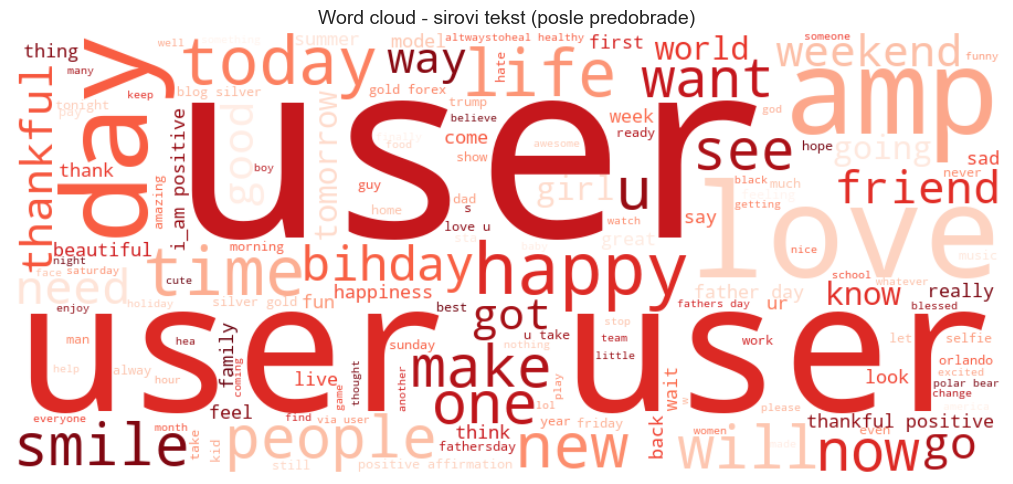

In [303]:
processed_text = ' '.join(df['tweet'].dropna().astype(str).tolist())

wc = WordCloud(width=900, height=400, background_color='white',
               max_words=150, colormap='Reds').generate(raw_text)

plt.figure(figsize=(12, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word cloud - sirovi tekst (posle predobrade)', fontsize=14)
plt.tight_layout()
plt.show()

## Reprezentacija teksta i klasifikacija

Za svaku metodu reprezentacije treniramo iste klasifikatore i čuvamo performanse. Svi rezultati se čuvaju u zajedničkoj tabeli za kasnije poređenje.

**Klasifikatori:** Logistička regresija, Naive Bayes, SVM, Random Forest  
**Metrike:** Accuracy, Precision, Recall, F1 (weighted)

In [304]:
results = []

def evaluate(name, X_tr, X_te, y_tr, y_te, classifiers):
    for clf_name, clf in classifiers:
        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_te)
        report = classification_report(y_te, y_pred, output_dict=True)
        results.append({
            'Reprezentacija': name,
            'Klasifikator':   clf_name,
            'Accuracy':       round(report['accuracy'], 4),
            'Precision':      round(report['weighted avg']['precision'], 4),
            'Recall':         round(report['weighted avg']['recall'], 4),
            'F1':             round(report['weighted avg']['f1-score'], 4),
        })
        print(f'{name} | {clf_name}: F1={round(report["weighted avg"]["f1-score"], 4)}')

    n = len(classifiers)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    if n == 1:
        axes = [axes]
    for ax, (clf_name, clf) in zip(axes, classifiers):
        y_pred = clf.predict(X_te)
        cm = confusion_matrix(y_te, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                    xticklabels=['Non-toxic', 'Toxic'],
                    yticklabels=['Non-toxic', 'Toxic'])
        ax.set_title(f'{clf_name}')
        ax.set_xlabel('Predicted')
        ax.set_ylabel('Actual')
    fig.suptitle(f'Confusion matrix - {name}', fontsize=13)
    plt.tight_layout()
    plt.show()

### Bag of Words

BoW predstavlja svaki dokument kao vektor frekvencija reči. Ignoriše redosled reči i semantiku, ali je jednostavan i efikasan.

In [305]:
bow_vec = CountVectorizer(max_features=10000)
X_bow_train = bow_vec.fit_transform(train_df['processed'])
X_bow_test  = bow_vec.transform(test_df['processed'])

print(f'BoW matrica - trening: {X_bow_train.shape}')

# Top 10 reči po klasi
feature_names = bow_vec.get_feature_names_out()
for label, name in [(1, 'Toxic'), (0, 'Non-toxic')]:
    idx = train_df[train_df['label'] == label].index
    freqs = X_bow_train[idx].sum(axis=0).A1
    top10 = sorted(zip(freqs, feature_names), reverse=True)[:10]
    print(f'\nTop 10 reči - {name}:')
    print([w for _, w in top10])

BoW matrica - trening: (33826, 10000)

Top 10 reči - Toxic:
['trump', 'not', 'drug', 'substance', 'exploiter', 'abuser', 'amp', 'white', 'woman', 'allahsoil']

Top 10 reči - Non-toxic:
['day', 'not', 'love', 'get', 'happy', 'go', 'life', 'make', 'today', 'like']


In [306]:
y_train = train_df['label'].reset_index(drop=True)
y_test  = test_df['label'].reset_index(drop=True)

BoW | Logistic Regression: F1=0.9559
BoW | Naive Bayes: F1=0.9498
BoW | SVM: F1=0.9531
BoW | Random Forest: F1=0.9529


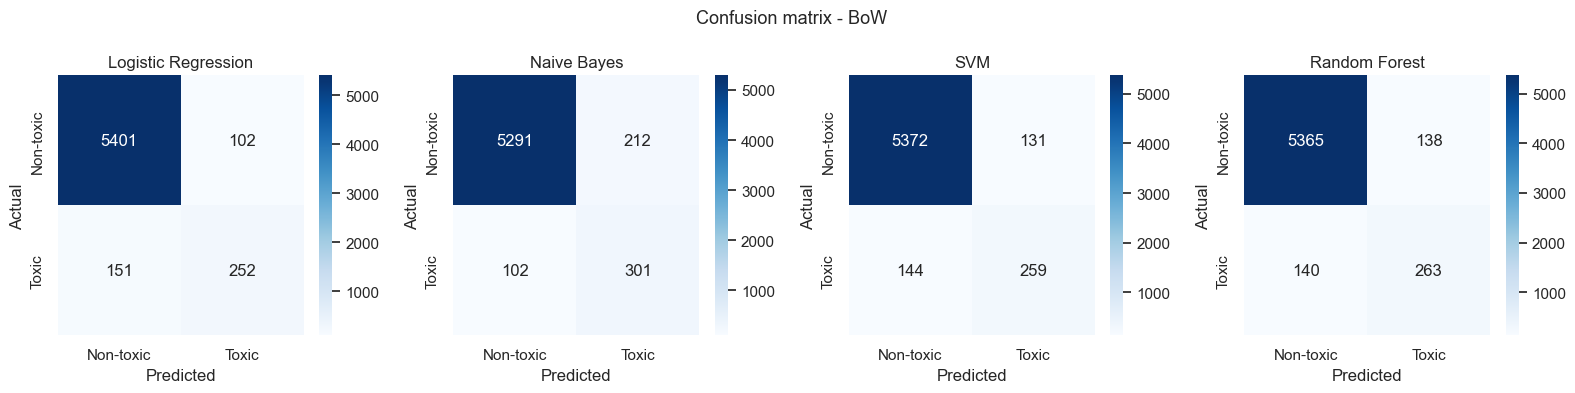

In [307]:
evaluate('BoW', X_bow_train, X_bow_test, y_train, y_test, clf_sparse)

Iako su F1 mere slične, iz matrica konfuzije vidimo da Naive Bayes pravi najmanje grešaka što se tiče toksičnih tvitova.

### TF-IDF

TF-IDF smanjuje uticaj čestih reči koje su manje informativne, a naglašava reči karakteristične za određenu klasu.

TF-IDF matrica - trening: (33826, 10000)


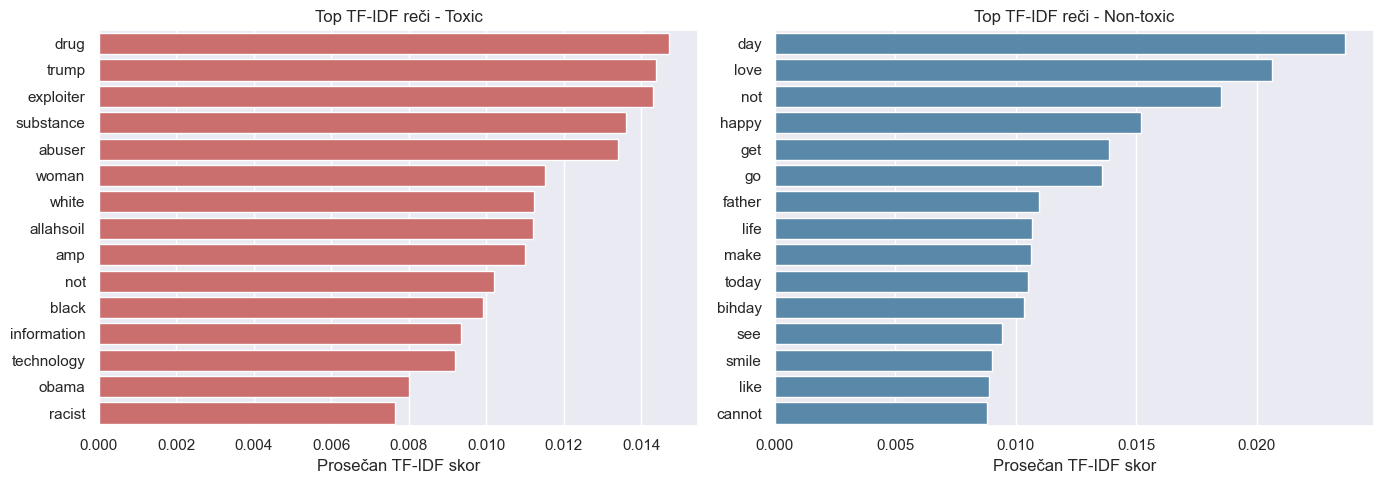

In [308]:
tfidf_vec = TfidfVectorizer(max_features=10000)
X_tfidf_train = tfidf_vec.fit_transform(train_df['processed'])
X_tfidf_test  = tfidf_vec.transform(test_df['processed'])

print(f'TF-IDF matrica - trening: {X_tfidf_train.shape}')

tfidf_names = tfidf_vec.get_feature_names_out()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (label, name, color) in zip(axes, [(1, 'Toxic', '#D95F5F'), (0, 'Non-toxic', '#4C8BB5')]):
    idx = train_df[train_df['label'] == label].index
    scores = X_tfidf_train[idx].mean(axis=0).A1
    top15 = sorted(zip(scores, tfidf_names), reverse=True)[:15]
    words, vals = zip(*[(w, s) for s, w in top15])
    sns.barplot(x=list(vals), y=list(words), ax=ax, color=color)
    ax.set_title(f'Top TF-IDF reči - {name}')
    ax.set_xlabel('Prosečan TF-IDF skor')
plt.tight_layout()
plt.show()

TF-IDF | Logistic Regression: F1=0.9514
TF-IDF | Naive Bayes: F1=0.9539
TF-IDF | SVM: F1=0.955
TF-IDF | Random Forest: F1=0.9506


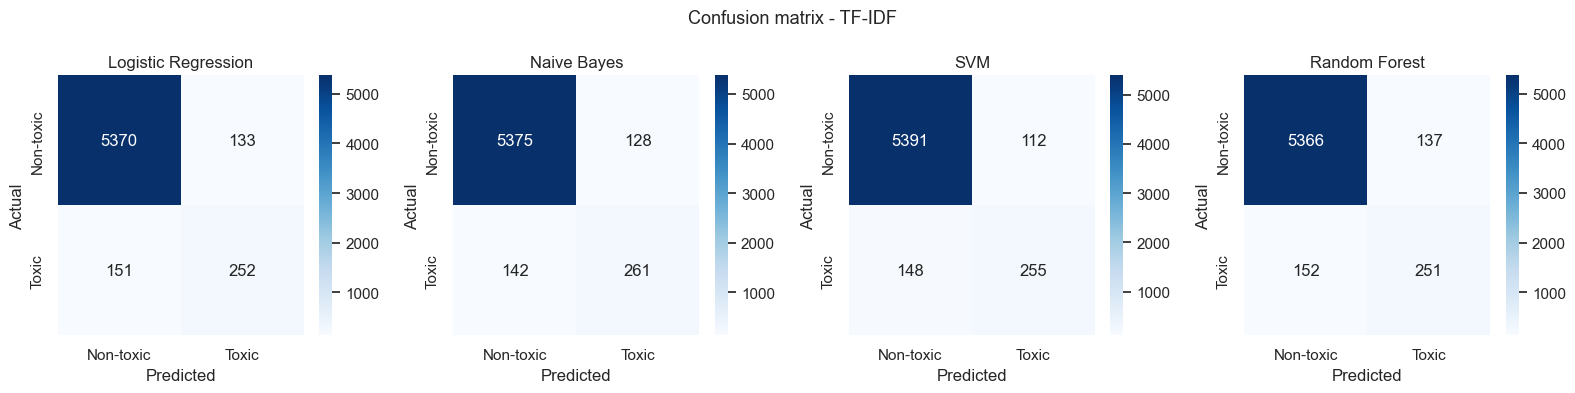

In [309]:
evaluate('TF-IDF', X_tfidf_train, X_tfidf_test, y_train, y_test, clf_sparse)

### Word2Vec

Word2Vec trenira vektorske reprezentacije reči na osnovu konteksta. Tvit se predstavlja kao prosek vektora svih njegovih reči.

In [310]:
w2v_model = Word2Vec(
    sentences=train_df['tokens'].tolist(),
    vector_size=100, window=5, min_count=2, workers=4, seed=42
)

# Najbliže reči za ključne pojmove
for word in ['hate', 'love', 'kill']:
    if word in w2v_model.wv:
        similar = w2v_model.wv.most_similar(word, topn=5)
        print(f'{word}: {[w for w, _ in similar]}')

hate: ['non', 'racist', 'talk', 'attract', 'hillary']
love: ['smile', 'beautiful', 'selfie', 'photooftheday', 'friend']
kill: ['hateful', 'clinton', 'mass', 'politician', 'shoot']


Word2Vec | Logistic Regression: F1=0.8956
Word2Vec | Naive Bayes: F1=0.6643
Word2Vec | SVM: F1=0.9105
Word2Vec | Random Forest: F1=0.9188


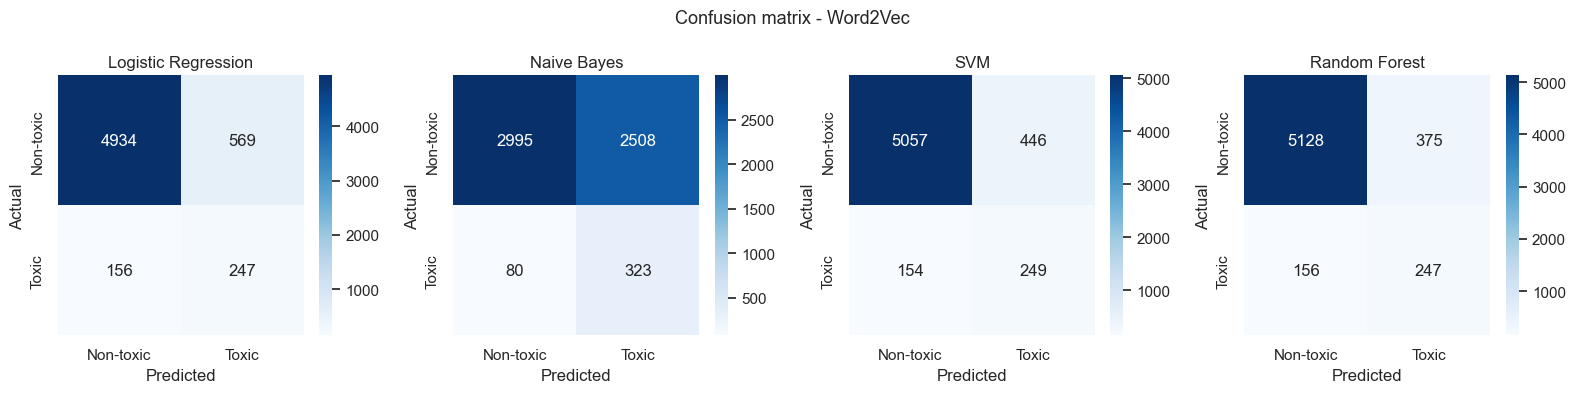

In [311]:
def tokens_to_vector(tokens, model):
    vecs = [model.wv[w] for w in tokens if w in model.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(model.vector_size)

X_w2v_train = np.array([tokens_to_vector(t, w2v_model) for t in train_df['tokens']])
X_w2v_test  = np.array([tokens_to_vector(t, w2v_model) for t in test_df['tokens']])

evaluate('Word2Vec', X_w2v_train, X_w2v_test, y_train, y_test, clf_dense)

Naive Bayes u ovom slučaju daje loše rezultate za ne-toksične tvitove zato što GaussianNB pretpostavlja da su atributi normalno distribuirani i nezavisni jedni od drugih - što za Word2Vec embeddings nije slučaj.

### FastText

FastText proširuje Word2Vec - reči se predstavljaju kao suma vektora n-grama karaktera. Prednost je robustnost na pravopisne greške i nepoznate reči.

FastText | Logistic Regression: F1=0.8935
FastText | Naive Bayes: F1=0.6536
FastText | SVM: F1=0.9035
FastText | Random Forest: F1=0.9078


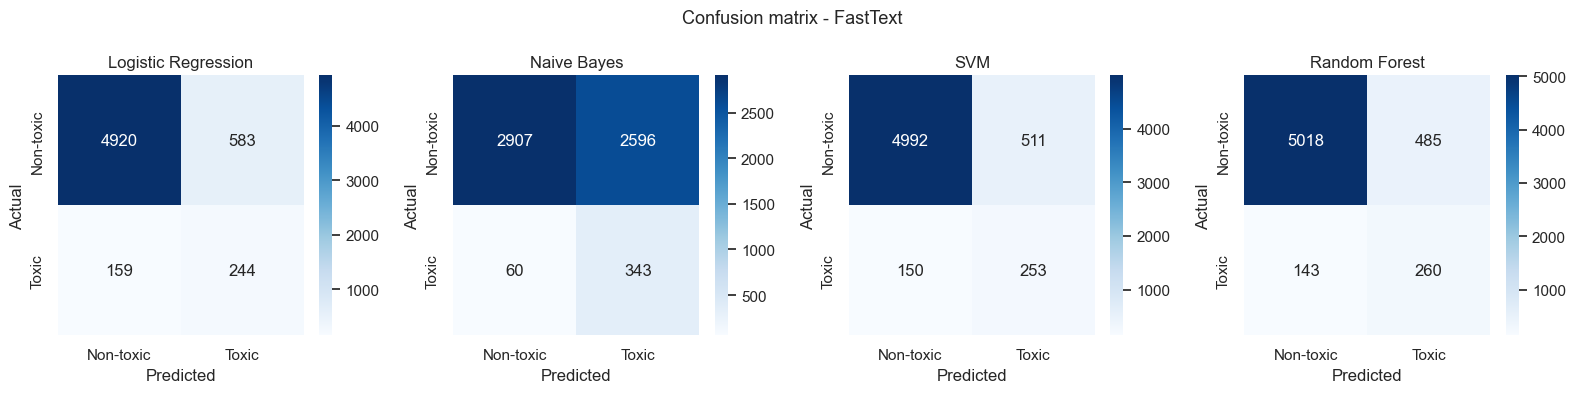

In [312]:
ft_model = FastText(
    sentences=train_df['tokens'].tolist(),
    vector_size=100, window=5, min_count=2, workers=4, seed=42
)

X_ft_train = np.array([tokens_to_vector(t, ft_model) for t in train_df['tokens']])
X_ft_test  = np.array([tokens_to_vector(t, ft_model) for t in test_df['tokens']])

evaluate('FastText', X_ft_train, X_ft_test, y_train, y_test, clf_dense)

### BERT (DistilBERT)

DistilBERT je lakša varijanta BERT modela. Koristimo `[CLS]` token kao reprezentaciju celog tvita. Koristimo `processed_no_lemma` tekst jer BERT sam razume morfologiju reči.

**Napomena:** Ekstrakcija embeddings-a je spora bez GPU-a. Koristimo prvih 2000 primera za demonstraciju.

Koriste se samo Logistička regresija i SVM jer Random Forest i Naive Bayes nisu efikasni na reprezentacijama koje daje BERT.

In [313]:
bert_name = 'distilbert-base-uncased'
bert_tok   = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name)
bert_model.eval()

def get_bert_embeddings(texts, batch_size=32):
    all_embeddings = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        encoded = bert_tok(batch, padding=True, truncation=True,
                           max_length=128, return_tensors='pt')
        with torch.no_grad():
            output = bert_model(**encoded)
        cls = output.last_hidden_state[:, 0, :].numpy()
        all_embeddings.append(cls)
    return np.vstack(all_embeddings)

N = 2000
train_texts_bert = train_df['processed_no_lemma'].iloc[:N].tolist()
test_texts_bert  = test_df['processed_no_lemma'].tolist()
y_train_bert     = y_train.iloc[:N]

print('Ekstrakcija BERT embeddings-a - trening skup...')
X_bert_train = get_bert_embeddings(train_texts_bert)
print('Ekstrakcija BERT embeddings-a - test skup...')
X_bert_test  = get_bert_embeddings(test_texts_bert)
print(f'BERT embeddings shape: {X_bert_train.shape}')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Ekstrakcija BERT embeddings-a - trening skup...
Ekstrakcija BERT embeddings-a - test skup...
BERT embeddings shape: (2000, 768)


BERT | Logistic Regression: F1=0.9385
BERT | SVM: F1=0.9299


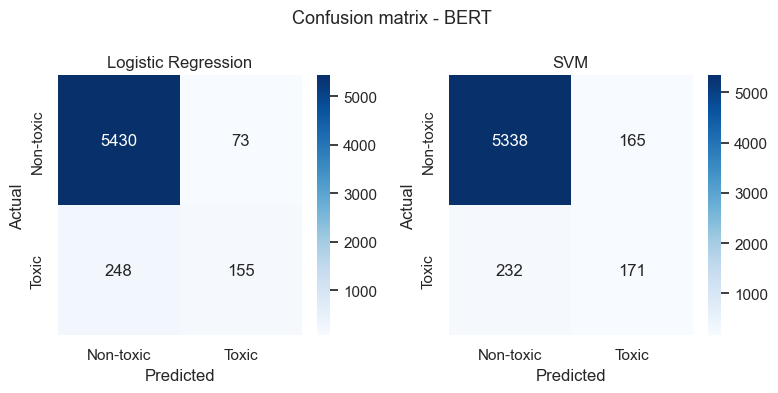

In [314]:
clf_bert = [
    ('Logistic Regression', LogisticRegression(max_iter=1000)),
    ('SVM',                 LinearSVC(max_iter=2000)),
]
evaluate('BERT', X_bert_train, X_bert_test, y_train_bert, y_test, clf_bert)

Na ovaj način su postignuti najbolji rezultati prepoznavanja ne-toksičnih tvitova (samo 73 je pogrešno klasifikovano), dok je za toksične više klasifikovano pogrešno nego ispravno.

### BERTweet

BERTweet je BERT model pretreniran na 850 miliona engleskih tvitova, što ga čini posebno pogodnim za analizu Twitter sadržaja. Za razliku od DistilBERT-a koji je treniran na opštem tekstu, BERTweet nativno razume Twitter-specifičan jezik - sleng, emoji i skraćenice - pa ga koristimo nad sirovim, neobrađenim tvitovima.

## Uticaj predobrade na reprezentacije i klasifikatore

Fiksiramo **TF-IDF + Logistička regresija** kao baseline i pokrećemo 4 varijante da izmerimo doprinos pojedinih koraka predobrade.

In [315]:
df_raw = pd.read_csv('twitter_toxic_tweets.csv', encoding='latin1')
df_raw = df_raw.drop_duplicates(subset='tweet').reset_index(drop=True)

X_raw_train, X_raw_test, y_abl_train, y_abl_test = train_test_split(
    df_raw['tweet'], df_raw['label'], test_size=0.2, random_state=42, stratify=df_raw['label']
)

def ablation_run(name, X_tr, X_te, y_tr, y_te):
    vec = TfidfVectorizer(max_features=10000)
    Xtr = vec.fit_transform(X_tr)
    Xte = vec.transform(X_te)
    clf = LogisticRegression(max_iter=1000)
    clf.fit(Xtr, y_tr)
    y_pred = clf.predict(Xte)
    report = classification_report(y_te, y_pred, output_dict=True)
    return {
        'Varijanta':      name,
        'Accuracy':       round(report['accuracy'], 4),
        'F1':             round(report['weighted avg']['f1-score'], 4),
        'Recall (Toxic)': round(report['1']['recall'], 4),
        'Broj atributa':  Xtr.shape[1]
    }

ablation_results = []

# Varijanta 1 — sirovi tekst
ablation_results.append(ablation_run(
    'Sirovi tekst', X_raw_train, X_raw_test, y_abl_train, y_abl_test
))

# Varijanta 2 — samo uklanjanje šuma
ablation_results.append(ablation_run(
    'Uklanjanje šuma',
    X_raw_train.apply(remove_noise),
    X_raw_test.apply(remove_noise),
    y_abl_train, y_abl_test
))

# Varijanta 3 — puna predobrada bez augmentacije
def full_preprocess(texts):
    return texts.apply(remove_noise).apply(normalize).apply(
        lambda t: ' '.join(
            [w for w in lemmatize(tokenizer.tokenize(t)) if w not in stop_words_filtered]
        )
    )

ablation_results.append(ablation_run(
    'Puna predobrada',
    full_preprocess(X_raw_train),
    full_preprocess(X_raw_test),
    y_abl_train, y_abl_test
))

# Varijanta 4 — puna predobrada sa augmentacijom
ablation_results.append(ablation_run(
    'Predobrada + augmentacija',
    train_df['processed'],
    full_preprocess(X_raw_test),
    y_train, y_abl_test
))

abl_df = pd.DataFrame(ablation_results)
abl_df

,Varijanta,Accuracy,F1,Recall (Toxic),Broj atributa
0,Sirovi tekst,0.9462,0.9312,0.2382,10000
1,Uklanjanje šuma,0.9470,0.9327,0.2506,10000
2,Puna predobrada,0.9487,0.9355,0.2730,10000
3,Predobrada + augmentacija,0.9516,0.9510,0.6203,10000


Vidimo da svaki korak predobrade pomalo povećava recall, odnosno procenat toksičnih tvitova koji su klasifikovani kao toksični, što znači da modeli postižu sve bolje performanse. Međutim, ono što dovodi do najvećeg skoka recall-a je augmentacija podataka. Pošto je dataset veoma nebalansiran na početku, tj. toksični tvitovi su u manjini, augmentacijom dataset postaje bolje balansiran i samim tim se poboljšavaju performanse modela.

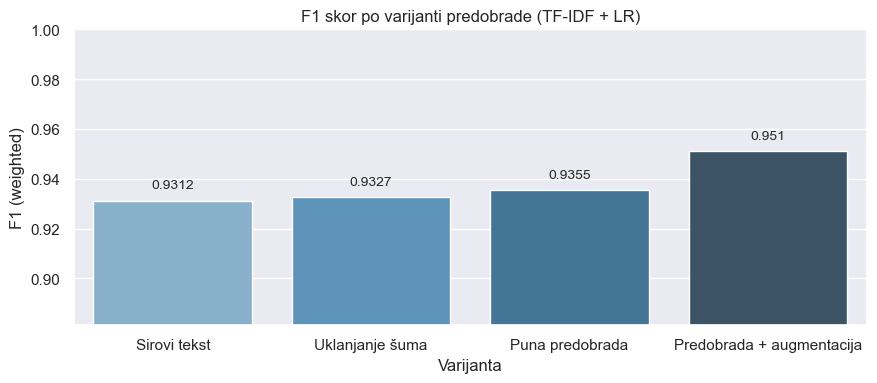

In [316]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=abl_df, x='Varijanta', y='F1', palette='Blues_d', ax=ax)
ax.set_title('F1 skor po varijanti predobrade (TF-IDF + LR)')
ax.set_ylabel('F1 (weighted)')
ax.set_ylim(abl_df['F1'].min() - 0.05, 1.0)
for bar, val in zip(ax.patches, abl_df['F1']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            str(val), ha='center', fontsize=10)
plt.tight_layout()
plt.show()

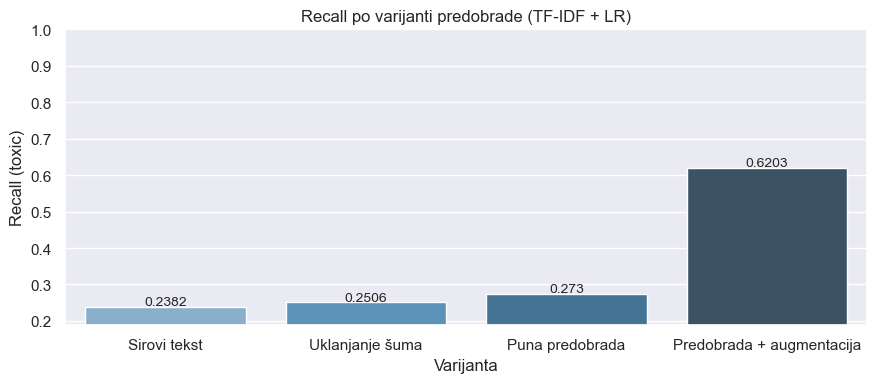

In [317]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=abl_df, x='Varijanta', y='Recall (Toxic)', palette='Blues_d', ax=ax)
ax.set_title('Recall po varijanti predobrade (TF-IDF + LR)')
ax.set_ylabel('Recall (toxic)')
ax.set_ylim(abl_df['Recall (Toxic)'].min() - 0.05, 1.0)
for bar, val in zip(ax.patches, abl_df['Recall (Toxic)']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            str(val), ha='center', fontsize=10)
plt.tight_layout()
plt.show()

## Analiza rezultata

Poredimo sve kombinacije reprezentacija i klasifikatora na osnovu prikupljenih rezultata.

In [318]:
results_df = pd.DataFrame(results)
results_df.sort_values('F1', ascending=False)

,Reprezentacija,Klasifikator,Accuracy,Precision,Recall,F1
0,BoW,Logistic Regression,0.9572,0.9550,0.9572,0.9559
6,TF-IDF,SVM,0.9560,0.9543,0.9560,0.9550
5,TF-IDF,Naive Bayes,0.9543,0.9536,0.9543,0.9539
2,BoW,SVM,0.9534,0.9528,0.9534,0.9531
3,BoW,Random Forest,0.9529,0.9528,0.9529,0.9529
4,TF-IDF,Logistic Regression,0.9519,0.9509,0.9519,0.9514
7,TF-IDF,Random Forest,0.9511,0.9502,0.9511,0.9506
1,BoW,Naive Bayes,0.9468,0.9542,0.9468,0.9498
16,BERT,Logistic Regression,0.9456,0.9375,0.9456,0.9385
17,BERT,SVM,0.9328,0.9277,0.9328,0.9299


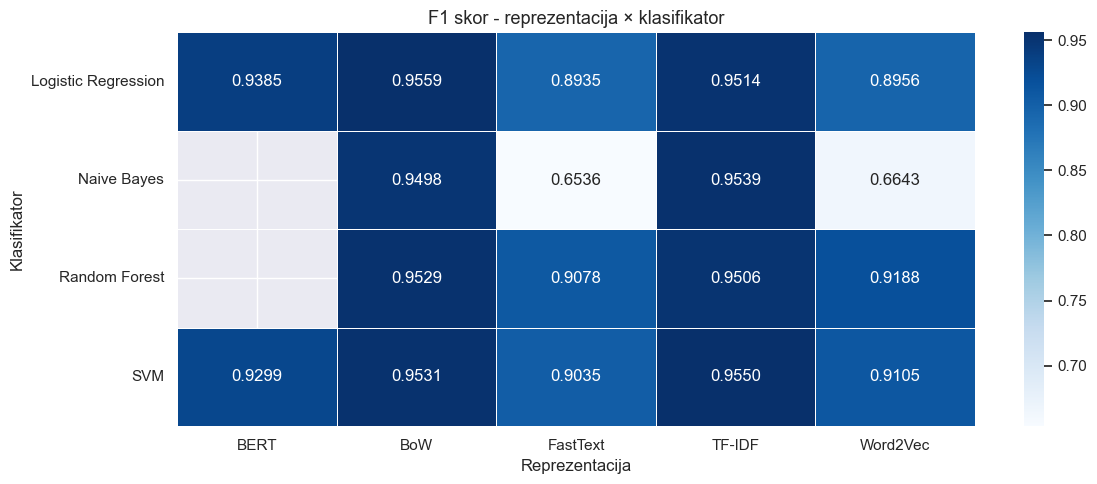

In [319]:
pivot = results_df.pivot(index='Klasifikator', columns='Reprezentacija', values='F1')

plt.figure(figsize=(12, 5))
sns.heatmap(pivot, annot=True, fmt='.4f', cmap='Blues',
            linewidths=0.5, linecolor='white')
plt.title('F1 skor - reprezentacija × klasifikator', fontsize=13)
plt.tight_layout()
plt.show()

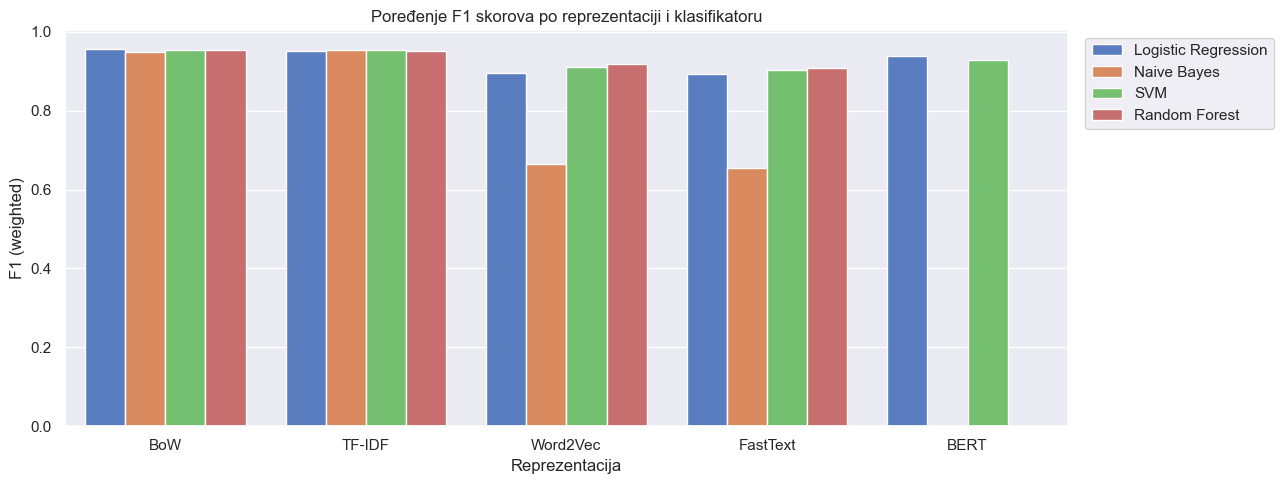

In [320]:
plt.figure(figsize=(13, 5))
sns.barplot(data=results_df, x='Reprezentacija', y='F1',
            hue='Klasifikator', palette='muted')
plt.title('Poređenje F1 skorova po reprezentaciji i klasifikatoru')
plt.ylabel('F1 (weighted)')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

Na osnovu prikazanih rezultata mogu se izvući sledeći zaključci:

**Reprezentacije:** Pomoću TF-IDF se postižu slični rezultati kao pomoću BoW. Word2Vec i FastText daju lošije rezultate jer su trenirani na relativno malom korpusu kratkih tvitova - prosečni vektor gubi kontekstualne informacije. BERT modeli pokazuju prednost u razumevanju konteksta, a BERTweet posebno zbog domenski specifičnog predobučavanja.

**Klasifikatori:** SVM i logistička regresija dominiraju na svim reprezentacijama. Naive Bayes je najbrži ali i najslabiji, posebno na vektorskim reprezentacijama gde pretpostavka o nezavisnosti atributa ne važi. Random Forest je spor na visokodimenizionalnim prostorima bez značajnog povećanja performansi.

**Predobrada:** Analiza uticaja predobrade pokazuje da svaki korak predobrade doprinosi poboljšanju F1 skora. Augmentacija posebno poboljšava Recall toksične klase jer model dobija više primera manjinske klase.